In [14]:
from typing import TypedDict ,NotRequired
from langgraph.graph import StateGraph ,START,END 
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage 

In [15]:
llm = ChatGroq( model="openai/gpt-oss-20b",
    temperature=0.7)

In [16]:
class graph_State(TypedDict):
    input_text: str
    english_text : NotRequired[str]
    translated_text :NotRequired[str] 
    

In [17]:
def translate(state: graph_State):
    text = state["english_text"]

    res = llm.invoke(
        "Translate the following text into Hindi. "
        "Return only the Hindi translation:\n\n"
        f"{text}"
    )

    return {"translated_text": res.content}

In [18]:
graph = StateGraph(graph_State)

graph.add_node("translate",translate)

graph.add_edge(START,"translate")
graph.add_edge("translate",END) 

subgraph = graph.compile()




In [19]:
def chat_node(state:graph_State):
    user_question = state['input_text']
    res = llm.invoke(user_question)

    return {'english_text':res.content}




In [20]:
graph = StateGraph(graph_State)


graph.add_node("chat_node",chat_node)
graph.add_node("parent_translate_node",subgraph)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node','parent_translate_node')
graph.add_edge("parent_translate_node",END) 

parent_graph = graph.compile()





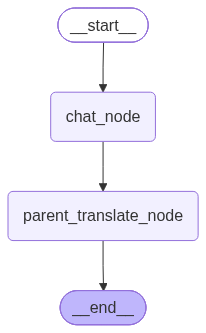

In [21]:
parent_graph

In [22]:
user_input = input("enter:")
res = parent_graph.invoke({"input_text":user_input})
res

{'input_text': 'explain subgraph in 50 wordsa',
 'english_text': 'A subgraph is a graph formed from a subset of vertices and edges of a larger graph, preserving adjacency. It captures a portion of the network, allowing analysis of local structure, connectivity, or community. Subgraphs are fundamental in graph theory, algorithms, and network science for data mining, visualization, and modeling.',
 'translated_text': 'एक उपग्राफ वह ग्राफ है जो बड़े ग्राफ के कुछ शिखरों और किनारों के उपसमुच्चय से बना होता है, जिसमें आसन्नता बनी रहती है। यह नेटवर्क के एक हिस्से को कैप्चर करता है, जिससे स्थानीय संरचना, कनेक्टिविटी या समुदाय का विश्लेषण संभव होता है। उपग्राफ ग्राफ सिद्धांत, एल्गोरिदम और नेटवर्क विज्ञान में डेटा माइनिंग, विज़ुअलाइज़ेशन और मॉडलिंग के लिए मूलभूत हैं।'}